# Step 2 - Normalization of the data

## 1. Load the modules & data

### 1.1 Load the data into a practical format

In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%load_ext rpy2.ipython

In [3]:
#Read the csv files

chevalier_path = "../data/nestorowa_singlecell_raw_data_taken_from_bonesis_paper.tsv"
QC_filtered_cells_path = "output/filtered_base.tsv"
qc_metrics_path = "../data/intermediary/cell_QC_metrics.tsv"
conversion_table_path = "output/ensembl_to_symbol.tsv"

chevalier_df = pd.read_csv(chevalier_path, sep="\t", index_col=0)
df_qc_filtered_data = pd.read_csv(QC_filtered_cells_path, sep="\t", index_col=0)
qc_metrics_df = pd.read_csv(qc_metrics_path, sep="\t", index_col=0)
conversion_table_df = pd.read_csv(conversion_table_path, sep="\t", index_col=0)

# Create a dictionary for quick lookup
id_to_symbol = conversion_table_df['symbol'].to_dict()

In [ ]:
#Compare the size of the df
n_genes, n_cells = df_qc_filtered_data.shape

print(f"Chevalier df shape: {chevalier_df.shape}")
print(f"Our Qc-filtered data shape: {df_qc_filtered_data.shape}")

Chevalier df shape: (4768, 1656)
Our Qc-filtered data shape: (43152, 1691)


### 1.2 Filter out low expression genes

The goal here is to get rid of gene that might have a null expression in almost all cells, so that they are not counted as HVG that we will not be able to use in our later analysis.

Text(0, 0.5, 'Frequency')

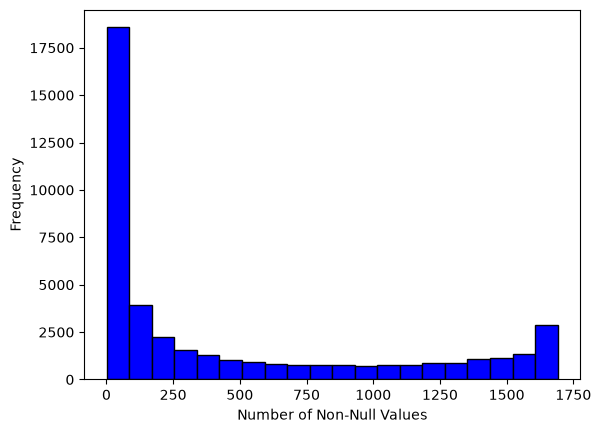

In [ ]:
df_filtered = df_qc_filtered_data.copy()

#Create a df counting the number of non null values for each row (gene) in the filtered df
non_null_counts =  (df_filtered != 0.0).sum(axis=1)


#plot a histogram of the non null counts
import matplotlib.pyplot as plt
non_null_counts.plot(kind="hist", bins=20, edgecolor="black", color="blue")
plt.xlabel("Number of Non-Null Values")
plt.ylabel("Frequency")

In [ ]:
# Counting genes with at least xx non-null values (cells)

for k in [0,1,np.floor(cells/500),np.floor(cells/100), np.floor(cells/50),np.floor(cells/10)]:
    subset_index = df_filtered.index[non_null_counts <= k].tolist()
    count = len(subset_index)

    print(f"=== Lignes avec au moins {k} valeurs non-nulles ===")
    print(f"Nombre de personnes/cellules : {count}")
    print(f"Liste des identifiants/index : {subset_index}\n")

**Load the data into an AnnData object**

The use of scanpy requires to put data in AnnData format. We bind the previously QC filtered data with its metrics to be able to plot some visualisations.

In [ ]:
#Getting data in anndata format
df_data = df_qc_filtered_data.copy()

#Converting into int
float_cols = df_data.select_dtypes(include=['float', 'float64']).columns
df_data[float_cols] = df_data[float_cols].astype("int64")

# Get cells in lines and genes in columns
df_data = df_data.T

#Filter the qc metrics on the conserved genes
common_cells = df_data.index.intersection(qc_metrics_df.index)
df_metrics_filtered = qc_metrics_df.loc[common_cells]

adata = ad.AnnData(X=df_data.values, obs=df_metrics_filtered)

#Get a copy of the original gene names in the var dataframe
adata.var['gene_names'] = df_data.columns

#Get a copy of the data
adata.layers["counts"] = adata.X.copy()

print(adata)

In [ ]:
#Visualize the counts distribution
p1= sns.histplot(data=adata.obs, x='raw_total_reads', bins=50, kde=True)

## 2. Normalization of the matrix

The goal of the normalization process i sto compensate for variation due to sampling effects.

Three main methods are mentionned on sc-best-practices.org:
- shifted logarithm
- scran nnormalization
- analytic Pearson's residues approximation.

The article from **Nestorowa et al.** mentions using two processes for normalization:
- resizing the data using an scran method described in **Lun et al. (2016)**
- reshaping the data with a log2 transformation.

In [ ]:
#Define the number of genes that will be selected by the different methods
nb_feature = 5000

### 2.1 Normalization by logarithmic shift

Start by applying the log shift transformation.

In [ ]:
scales_counts = sc.pp.normalize_total(adata, layer = "counts",target_sum=None, inplace=False)
# log1p transform
adata.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

**Visualization**

Comparing visually the distribution of the raw counts before and after transformation. Here it is clear that the logarithmic shift enabled to reduce the variance, as intended.

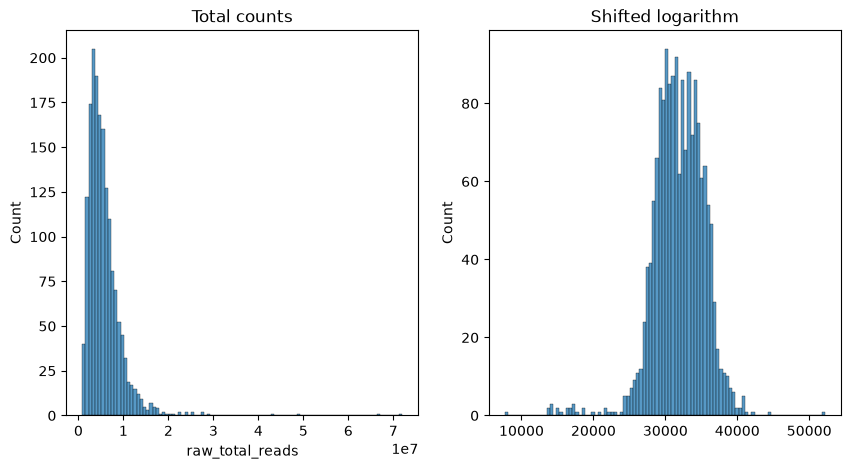

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["raw_total_reads"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.savefig("output/total_counts_histogram_log_shift.png", dpi=300)
plt.show()

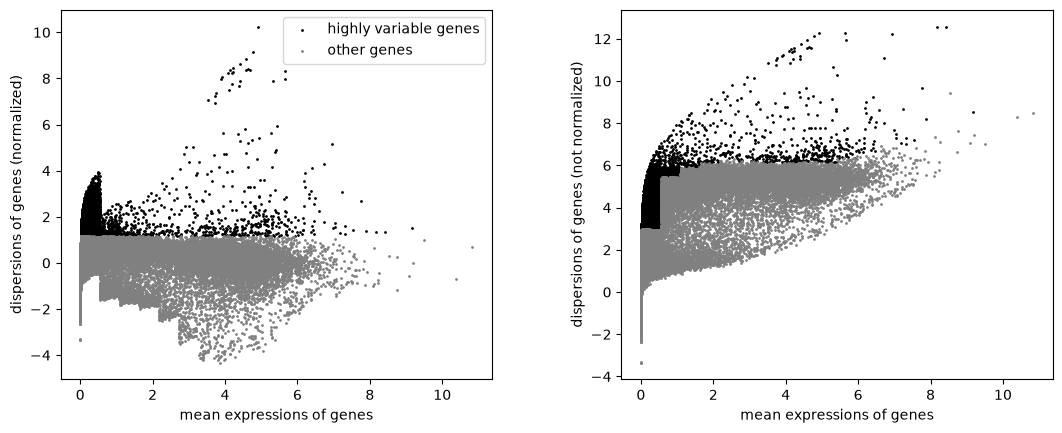

In [ ]:
# Computing HVG with the normalized counts
sc.pp.highly_variable_genes(
    adata, layer="log1p_norm", flavor="seurat", n_top_genes=nb_feature
)

#Save in a special layer
adata.var["hvg_log_shift"]=adata.var["highly_variable"].copy()

# Visualisation
sc.pl.highly_variable_genes(adata)

In [12]:
#Getting the gene list from adata highly variable, where variable is True
hvg_genes_log = adata.var['gene_names'][adata.var['highly_variable']].tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_log = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_genes_log]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_log) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")

Number of common genes: 861


### 2.2 Normalization by scran method

This is the method that was used in **Lun et al.** .

In [13]:
from scipy.sparse import csr_matrix

In [14]:
%%R
library(scran)
library(BiocParallel)

R[write to console]: Loading required package: SingleCellExperiment

R[write to console]: Loading required package: SummarizedExperiment

R[write to console]: Loading required package: MatrixGenerics

R[write to console]: Loading required package: matrixStats

R[write to console]: 
Attaching package: ‘MatrixGenerics’


R[write to console]: The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowC

In [26]:
print (adata)

AnnData object with n_obs × n_vars = 1691 × 43152
    obs: 'cell', 'raw_total_reads', 'mapped_reads', 'assigned_feature_reads', 'nuclear_reads', 'detected_genes', 'mitochondrial_reads', 'ercc_reads', 'mito_pct_mapped', 'ercc_pct_mapped', 'pass_nuclear', 'pass_genes', 'pass_mito', 'pass_ercc', 'pass_all'
    var: 'gene_names'
    layers: 'counts'


In [27]:
counts_mtx = adata.layers["counts"].T.copy()

In [28]:
%%R -i counts_mtx -o size_factors

target_lib <- "/home/lverhaeghe/miniconda3/envs/single_cell/lib/R/library"
.libPaths(c(target_lib, .libPaths()))

suppressPackageStartupMessages({
    library(SingleCellExperiment)
    library(scran)
    library(BiocParallel)
})

# 1. Converting the matrix in CsparseMatrix
counts_sparse <- as(counts_mtx, "CsparseMatrix")

# 2. Creating SingleCellExperiment object
sce_obj <- SingleCellExperiment(assays = list(counts = counts_sparse))

# 3. Pre-clustering
set.seed(100)
quick_clusters <- quickCluster(sce_obj)

# 4. Computing size factors
sf_res <- calculateSumFactors(sce_obj, cluster = quick_clusters, BPPARAM = MulticoreParam(workers = 4))

# 5. Conversion of the result
if (inherits(sf_res, "SingleCellExperiment")) {
    size_factors <- as.numeric(sizeFactors(sf_res))
} else {
    size_factors <- as.numeric(sf_res)
}

In [ ]:
from scipy.sparse import issparse

adata.obs["scran_size_factor"] = size_factors
sf_vec = adata.obs["scran_size_factor"].values[:, None]
counts_X = adata.layers["counts"]

# 4. Normalization scran & log2
if issparse(counts_X):
    # (counts / size_factor) then log2(1 + x)
    X_norm = counts_X.multiply(1.0 / sf_vec).tocsr()
    # log2(1 + x) = log1p(x) / ln(2)
    X_norm.data = np.log1p(X_norm.data) / np.log(2)
else:
    X_norm = np.log2((counts_X / sf_vec) + 1.0)

# 5. Save in adata
adata.layers["scran_normalized"] = X_norm
adata.X = X_norm.copy()

Normalisation terminée avec 'scran_size_factor'.


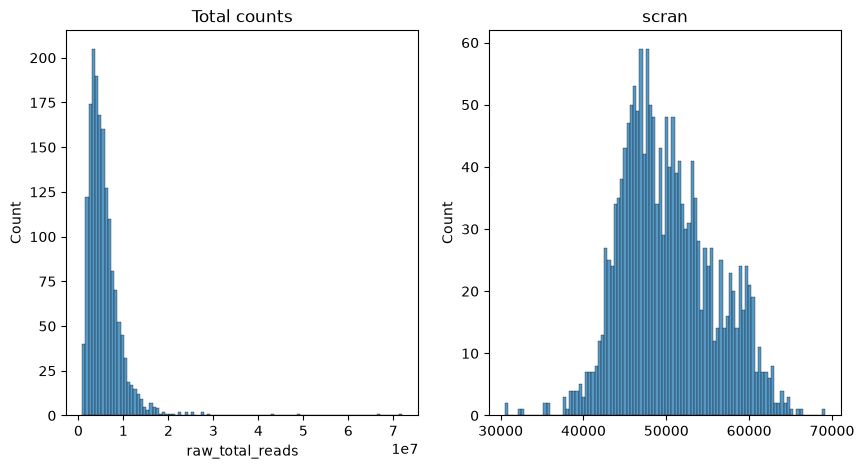

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["raw_total_reads"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["scran_normalized"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("scran")
plt.show()

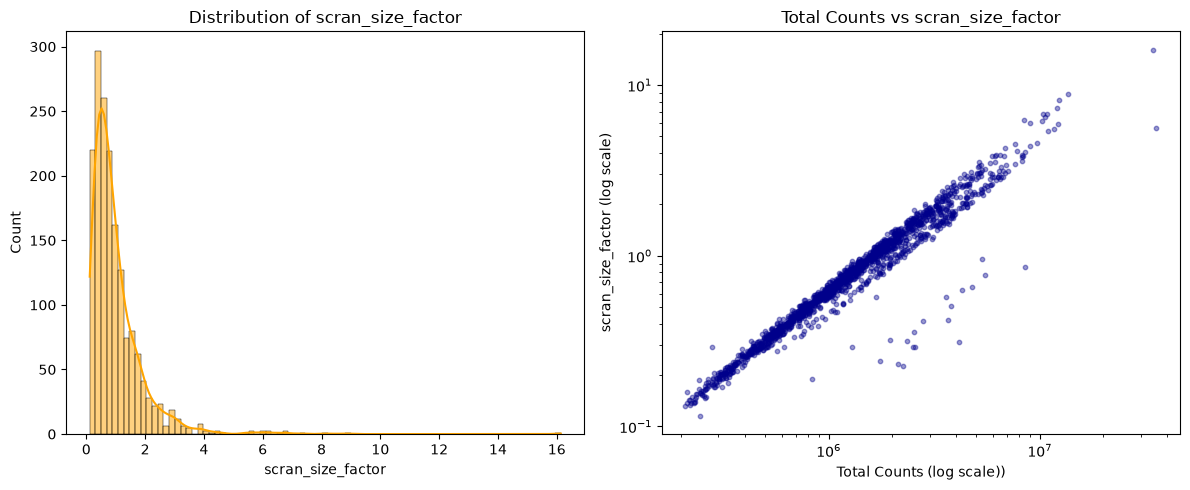

In [ ]:
# Calcul du nombre total de UMI par cellule si pas encore présent
if "total_counts" not in adata.obs:
    adata.obs["total_counts"] = (
        adata.layers["counts"].sum(axis=1)
        if "counts" in adata.layers
        else counts_X.sum(axis=1)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histogram
sns.histplot(
    adata.obs["scran_size_factor"], kde=True, ax=axes[0], color="orange"
)
axes[0].set_title("Distribution of scran_size_factor")
axes[0].set_xlabel("scran_size_factor")

# 2. Correlation between gene counts and size factor
axes[1].scatter(
    adata.obs["total_counts"],
    adata.obs["scran_size_factor"],
    alpha=0.4,
    s=10,
    c="darkblue",
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Total Counts (log scale))")
axes[1].set_ylabel("scran_size_factor (log scale)")
axes[1].set_title("Total Counts vs scran_size_factor")

plt.tight_layout()
plt.show()

In [32]:
import scanpy as sc

# 1. Selecting HVG
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=5000,
    flavor="seurat",  # or "cell_ranger"
    layer="scran_normalized",
    subset=False,
)

In [33]:
#Getting the gene list from adata highly variable, where variable is True
hvg_scran = adata.var['gene_names'][adata.var['highly_variable']].tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_scran = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_scran]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_scran) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")

Number of common genes: 897


### 2.4 Compare the different normalization methods

### 2.3 Normalization using Pearson's residues

In [35]:
# Computing pearson's residues
pearson_results = sc.experimental.pp.normalize_pearson_residuals(adata,layer = "counts")

# Selecting HVG
sc.experimental.pp.highly_variable_genes(
    adata,
    layer = "counts", 
    flavor="pearson_residuals", 
    n_top_genes=5000
)

/tmp/ipykernel_3386/3858468604.py:2: UserWarning: `normalize_pearson_residuals()` expects raw count data, but non-integers were found.
  pearson_results = sc.experimental.pp.normalize_pearson_residuals(adata,layer = "counts")


: 

In [ ]:
#Getting the gene list from adata highly variable, where variable is True
hvg_genes_pearson = adata.var[adata.var['highly_variable']].index.tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_pearson = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_genes_pearson]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_pearson) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")


Number of common genes: 1240


In [ ]:
#Annotating mitochondrial genes
grcm38_mito_ensembl = [f"ENSMUSG000000{i}" for i in range(64336, 64362)] + \
                      [f"ENSMUSG000000{i}" for i in range(64363, 64373)] + \
                      ["ENSMUSG00000065947"]

assert len(grcm38_mito_ensembl) == 37